In [1]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
)

In [2]:
df = pd.read_csv("../data/processed/logistics_shipments_processed.csv")

print(df.shape)

df.head()

(1000, 26)


,shipment_id,booking_datetime,dispatch_datetime,expected_delivery_datetime,actual_delivery_datetime,origin_city,destination_city,distance_km,package_type,vehicle_type,...,warehouse_load,customer_priority,fuel_price_per_litre,fuel_consumption_litres,expected_travel_hours,delivery_cost,is_weekend,is_holiday,delay_minutes,delayed
0,SHP0000001,2026-02-26 11:09:26.516168,2026-02-26 12:09:26.516168,2026-02-27 19:32:14.516168,2026-02-27 20:42:14.516168,Hyderabad,Delhi,1569.24,Furniture,Mini Truck,...,High,Same Day,92.17,143.26,31.38,3002.67,False,False,70,False
1,SHP0000002,2025-07-17 04:52:22.176702,2025-07-17 09:52:22.176702,2025-07-17 15:18:46.176702,2025-07-17 16:29:46.176702,Chandigarh,Delhi,299.12,Medicine,Van,...,Low,Standard,107.45,28.81,5.44,693.02,False,False,71,False
2,SHP0000003,2025-10-16 11:02:07.584089,2025-10-17 00:02:07.584089,2025-10-18 08:05:07.584089,2025-10-18 08:47:07.584089,Kanpur,Hyderabad,1282.16,Document,Truck,...,Low,Same Day,101.49,144.49,32.05,2464.81,False,False,42,False
3,SHP0000004,2025-09-27 13:06:16.838261,2025-09-28 04:06:16.838261,2025-09-29 03:24:16.838261,2025-09-29 03:45:16.838261,Dehradun,Nagpur,1281.48,Medicine,Van,...,Low,Standard,111.66,120.20,23.30,2403.74,True,False,21,False
4,SHP0000005,2026-04-02 21:15:59.209876,2026-04-03 18:15:59.209876,2026-04-04 09:45:59.209876,2026-04-04 10:30:59.209876,Nagpur,Pune,775.17,Furniture,Mini Truck,...,Low,Standard,101.56,78.38,15.50,1483.35,False,False,45,False


In [3]:
datetime_columns = [
    "booking_datetime",
    "dispatch_datetime",
    "expected_delivery_datetime",
    "actual_delivery_datetime",
]

for col in datetime_columns:
    df[col] = pd.to_datetime(df[col])

df["booking_month"] = df["booking_datetime"].dt.month
df["booking_day"] = df["booking_datetime"].dt.day
df["booking_weekday"] = df["booking_datetime"].dt.weekday
df["booking_hour"] = df["booking_datetime"].dt.hour

In [4]:
features = [
    "origin_city",
    "destination_city",
    "distance_km",
    "package_type",
    "vehicle_type",
    "vehicle_speed_kmph",
    "shipment_weight_kg",
    "weather",
    "traffic_level",
    "route_type",
    "driver_experience_years",
    "warehouse_load",
    "customer_priority",
    "fuel_price_per_litre",
    "fuel_consumption_litres",
    "expected_travel_hours",
    "delivery_cost",
    "is_weekend",
    "is_holiday",
    "booking_month",
    "booking_day",
    "booking_weekday",
    "booking_hour",
]

X = df[features]
y = df["delayed"]

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

In [9]:
model = joblib.load("../models/random_forest_model.pkl")

print(model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['distance_km',
                                                   'vehicle_speed_kmph',
                                                   'shipment_weight_kg',
                                                   'driver_experience_years',
                                                   'fuel_price_per_litre',
                                                   'fuel_consumption_litres',
                                                   'expected_travel_hours',
                                                   'delivery_cost',
                                                   'booking_month',
                                                   'booking_day',
                                                   'booking_weekday',
                                                   'booking_hour']),
                                

In [10]:
y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))

print(classification_report(y_test, y_pred))

Accuracy: 0.94
              precision    recall  f1-score   support

       False       0.95      0.97      0.96       146
        True       0.92      0.85      0.88        54

    accuracy                           0.94       200
   macro avg       0.93      0.91      0.92       200
weighted avg       0.94      0.94      0.94       200



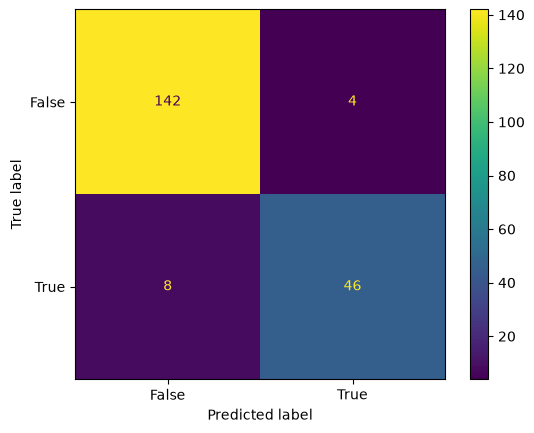

In [11]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
)

plt.show()

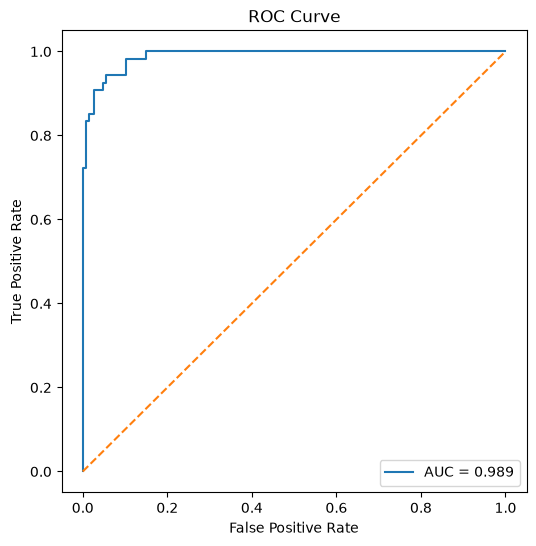

In [12]:
fpr, tpr, _ = roc_curve(
    y_test,
    y_prob,
)

auc = roc_auc_score(
    y_test,
    y_prob,
)

plt.figure(figsize=(6,6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {auc:.3f}",
)

plt.plot(
    [0,1],
    [0,1],
    "--",
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.show()

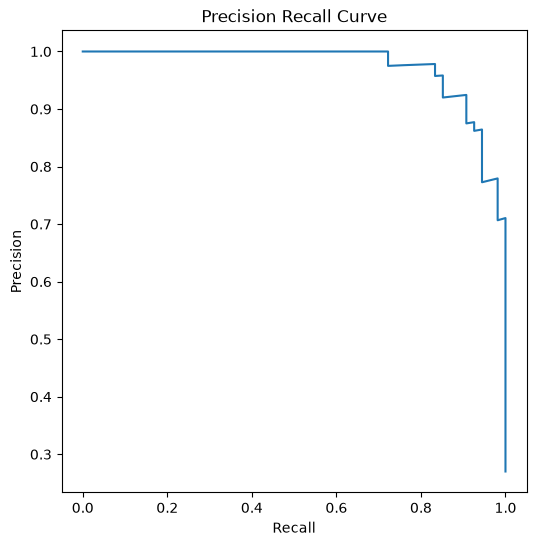

In [13]:
precision, recall, _ = precision_recall_curve(
    y_test,
    y_prob,
)

plt.figure(figsize=(6,6))

plt.plot(
    recall,
    precision,
)

plt.xlabel("Recall")

plt.ylabel("Precision")

plt.title("Precision Recall Curve")

plt.show()

In [14]:
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

importances = model.named_steps[
    "classifier"
].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances,
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False,
)

importance_df.head(20)

,Feature,Importance
65,cat__weather_Storm,0.277823
62,cat__weather_Clear,0.080368
6,num__expected_travel_hours,0.053094
66,cat__traffic_level_High,0.052754
63,cat__weather_Fog,0.048368
0,num__distance_km,0.043517
7,num__delivery_cost,0.043205
5,num__fuel_consumption_litres,0.040986
67,cat__traffic_level_Low,0.033674
64,cat__weather_Rain,0.026153


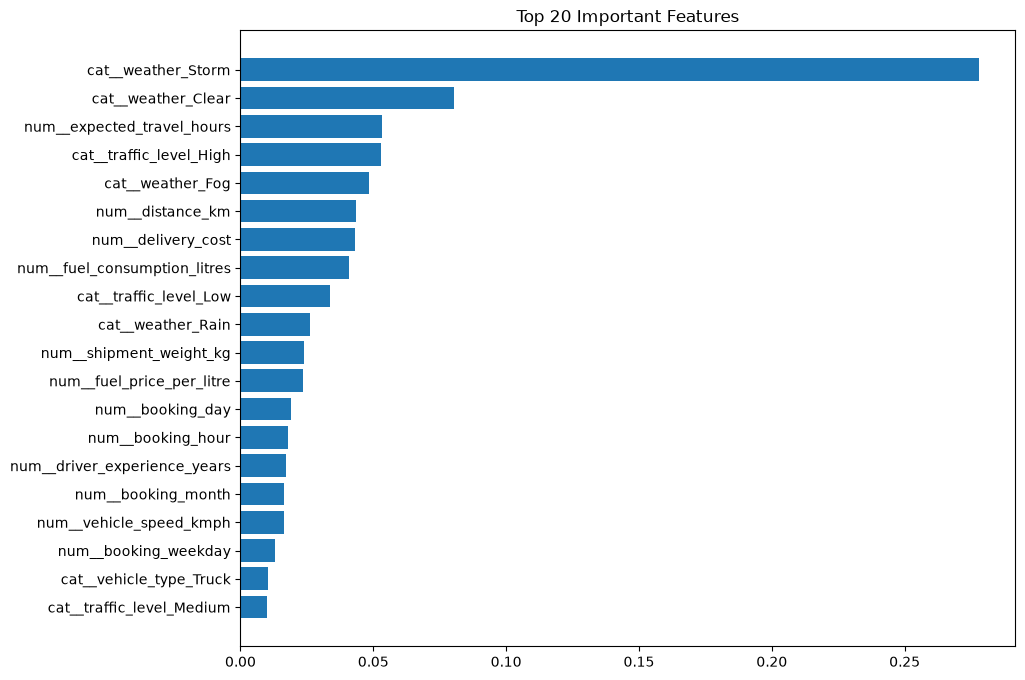

In [15]:
top20 = importance_df.head(20)

plt.figure(figsize=(10,8))

plt.barh(
    top20["Feature"],
    top20["Importance"],
)

plt.gca().invert_yaxis()

plt.title("Top 20 Important Features")

plt.show()

In [16]:
importance_df.to_csv(
    "../models/feature_importance.csv",
    index=False,
)

print("Feature importance saved successfully.")

Feature importance saved successfully.


In [17]:
print("=" * 60)
print("MODEL EVALUATION SUMMARY")
print("=" * 60)

print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"AUC Score : {auc:.4f}")

print("\nTop 10 Features")

print(
    importance_df.head(10).to_string(index=False)
)

MODEL EVALUATION SUMMARY
Accuracy : 0.9400
AUC Score : 0.9890

Top 10 Features
                     Feature  Importance
          cat__weather_Storm    0.277823
          cat__weather_Clear    0.080368
  num__expected_travel_hours    0.053094
     cat__traffic_level_High    0.052754
            cat__weather_Fog    0.048368
            num__distance_km    0.043517
          num__delivery_cost    0.043205
num__fuel_consumption_litres    0.040986
      cat__traffic_level_Low    0.033674
           cat__weather_Rain    0.026153
